# Pest Detection and Segmentation: finding and outlining each pest

**Business case:** Pests damage crops and cut yields. Farmers check fields by eye, which is slow, and often spray a whole field when only some plants are affected. A model that finds pests in crop photos allows targeted treatment.

**Goal:** Build a **segmentation model that finds each pest separately, outlines it and counts it** (instance segmentation). Knowing *how many* pests there are matters, because the count decides whether treatment is worth it.

**Data:** `images.zip` (crop photos) and `annotation.zip` (one `.xml` file per annotation with a box around each pest, in 11 folders named after the pest type).

**Approach:**
1. Read the XML files and clean them.
2. The dataset only has boxes, so **SAM** (a ready-made "segment anything" model) draws an outline inside each box.
3. Train **YOLOv8-seg**, which returns one outline and one confidence score per pest.
4. Evaluate on photos the model has never seen, including how accurate the pest **count** is.

**Colab: Runtime → Change runtime type → GPU (T4)** before running. Allow roughly 1 hour in total (about 15 minutes for the SAM outlines and about 30 to 45 minutes of training).

## What to know about the data
- **The annotations are boxes, not outlines.** That is why SAM is used to create the outlines. If SAM is switched off (`USE_SAM = False`), the boxes themselves are used as rectangle masks, which is faster but less precise.
- **The `<name>` field in the XML is not reliable** (numeric codes, wrong names, junk words such as "car"). So every pest is treated as one class, **"pest"**.
- **Some images have several XML files** (for example `01867.xml`, `01867-1.xml`). They are merged by the image name inside the file, so all pests of an image are kept together.
- One XML file is empty and a few boxes are broken. These are removed.
- Image sizes vary a lot (about 75×63 up to 4608×3456 pixels). YOLO resizes them automatically.

## Step 1. Install and download the data

In [ ]:
!pip install -q ultralytics
!wget -q -O images.zip "https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Client-Projects/AIPRCL-002-Pest-Control/images.zip"
!wget -q -O annotation.zip "https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Client-Projects/AIPRCL-002-Pest-Control/annotation.zip"
!mkdir -p pest/images pest/annotation
!unzip -q -o images.zip -d pest/images
!unzip -q -o annotation.zip -d pest/annotation
!ls pest/annotation

'asiatic rice borer'	    'wheat blossom midge'
'paddy stem maggot'	    'wheat phloeothrips'
'rice gall midge'	    'wheat sawfly'
'rice leaf caterpillar'     'white backed plant hopper'
'rice leaf roller'	    'yellow rice borer'
'small brown plant hopper'


## Step 2. Imports and settings

In [ ]:
import os, glob, random, shutil
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from ultralytics import YOLO, SAM

ANN_DIR = "/content/pest/annotation"
IMG_DIR = "/content/pest/images"
DS_DIR  = Path("/content/pest_yolo")      # the dataset in the format YOLO needs
RUNS    = "/content/runs"

SEED, IMGSZ, EPOCHS, BATCH = 42, 640, 50, 16
CONF = 0.25          # a detection is kept if the model is at least 25% sure
USE_SAM = True       # True = SAM outlines (about 15 min), False = boxes as masks (fast)

random.seed(SEED); np.random.seed(SEED)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Step 3. Read the XML files and match them to the photos
For every photo this collects all of its boxes (merging several XML files if needed), removes broken boxes, and adds the real photo size and file path.

In [ ]:
# 1) read every XML file: image name -> its boxes
images = {}
for xml_path in sorted(glob.glob(f"{ANN_DIR}/**/*.xml", recursive=True)):
    try:
        root = ET.parse(xml_path).getroot()
    except ET.ParseError:
        continue                                              # empty or broken file
    name = (root.findtext("filename") or Path(xml_path).stem + ".jpg").strip()
    item = images.setdefault(name, {
        "folder": os.path.basename(os.path.dirname(xml_path)).strip(),   # pest type = folder name
        "W": int(float(root.findtext("size/width") or 0)),
        "H": int(float(root.findtext("size/height") or 0)),
        "boxes": set()})
    for obj in root.findall("object"):
        b = obj.find("bndbox")
        if b is None:
            continue
        try:
            x0, y0, x1, y1 = [float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
        except (TypeError, ValueError):
            continue
        if x1 - x0 >= 2 and y1 - y0 >= 2:                     # drop broken / tiny boxes
            item["boxes"].add((x0, y0, x1, y1))

# 2) find every image file
path_by_name, path_by_stem = {}, {}
for dirpath, _, files in os.walk(IMG_DIR):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            path_by_name.setdefault(f, os.path.join(dirpath, f))
            path_by_stem.setdefault(Path(f).stem, os.path.join(dirpath, f))

# 3) one row per photo
rows = []
for name, it in images.items():
    path = path_by_name.get(name) or path_by_stem.get(Path(name).stem)
    if path is None or not it["boxes"]:
        continue
    with Image.open(path) as im:
        W, H = im.size                                        # real photo size
    sx = W / it["W"] if it["W"] else 1.0                      # in case the XML size differs
    sy = H / it["H"] if it["H"] else 1.0
    boxes = [(max(x0 * sx, 0), max(y0 * sy, 0), min(x1 * sx, W), min(y1 * sy, H)) for x0, y0, x1, y1 in it["boxes"]]
    rows.append({"image": name, "path": path, "folder": it["folder"], "W": W, "H": H, "boxes": boxes})

df = pd.DataFrame(rows)
assert len(df) > 0, "No photos matched the XML files - check the folders."
assert df["path"].map(lambda p: Path(p).stem).is_unique, "Two photos share the same file name."
print(f"XML names: {len(images)} | photos used: {len(df)} | pests (boxes): {df['boxes'].map(len).sum()}")

XML names: 1933 | photos used: 1933 | pests (boxes): 3134


## Step 4. Look at the data

Photos per pest type:
 folder
yellow rice borer            238
wheat blossom midge          207
wheat sawfly                 205
white backed plant hopper    202
rice gall midge              200
rice leaf roller             198
small brown plant hopper     165
rice leaf caterpillar        148
asiatic rice borer           143
paddy stem maggot            127
wheat phloeothrips           100

Pests per photo: {'mean': 1.6, '50%': 1.0, 'max': 41.0}
Average box size as a share of the photo: {'25%': 0.09, '50%': 0.224, '75%': 0.453}


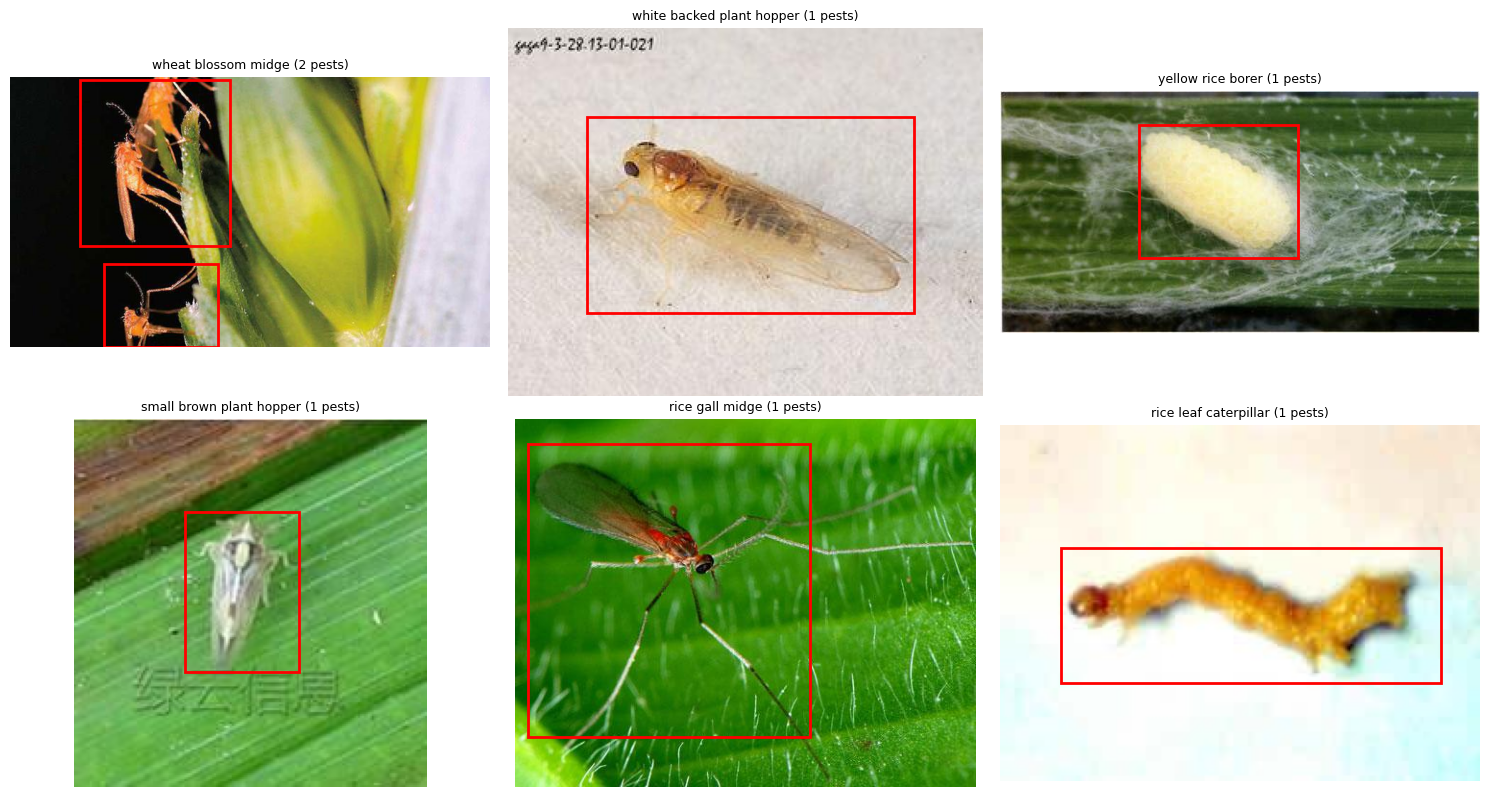

In [ ]:
df["n_pests"] = df["boxes"].map(len)
df["box_share"] = [np.mean([(x1 - x0) * (y1 - y0) / (w * h) for x0, y0, x1, y1 in b]) for b, w, h in zip(df["boxes"], df["W"], df["H"])]

print("Photos per pest type:\n", df["folder"].value_counts().to_string())
print("\nPests per photo:", df["n_pests"].describe()[["mean", "50%", "max"]].round(1).to_dict())
print("Average box size as a share of the photo:", df["box_share"].describe()[["25%", "50%", "75%"]].round(3).to_dict())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (_, r) in zip(axes.ravel(), df.sample(6, random_state=SEED).iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB"))
    for x0, y0, x1, y1 in r["boxes"]:
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="red", linewidth=2))
    ax.set_title(f"{r['folder']} ({r['n_pests']} pests)", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 5. Split the photos: 70% train, 15% validation, 15% test
The split is by photo (a photo is never in two groups) and keeps the same mix of pest types in each group. The model **learns** from the training photos, the validation photos are used during training to pick the best version, and the test photos are used **once at the end** to give an honest grade.

In [ ]:
train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df["folder"], random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df["folder"], random_state=SEED)
print(f"train: {len(train_df)} photos | val: {len(val_df)} | test: {len(test_df)}")
print("pests -> train:", train_df["n_pests"].sum(), "| val:", val_df["n_pests"].sum(), "| test:", test_df["n_pests"].sum())

train: 1353 photos | val: 290 | test: 290
pests -> train: 2208 | val: 456 | test: 470


## Step 6. Draw an outline for each pest and write the YOLO dataset
For every box, SAM proposes an outline. The outline is accepted only if its size is sensible compared with the box; otherwise the box itself is used. Each pest becomes one line in a label file: the class (0 = pest) followed by the outline points, scaled to 0-1.

In [ ]:
sam = SAM("sam_b.pt") if USE_SAM else None

def polygon_area(p):                                          # shoelace formula
    x, y = p[:, 0], p[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

def make_polygons(path, boxes):
    """One outline per box: SAM if it looks sensible, otherwise the box itself."""
    polys = [np.array([[x0, y0], [x1, y0], [x1, y1], [x0, y1]], float) for x0, y0, x1, y1 in boxes]
    kinds = ["box"] * len(boxes)
    if sam is not None:
        try:
            res = sam(path, bboxes=[list(b) for b in boxes], verbose=False)[0]
            if res.masks is not None and len(res.masks.xy) == len(boxes):
                for i, p in enumerate(res.masks.xy):
                    p = np.asarray(p, float)
                    x0, y0, x1, y1 = boxes[i]
                    if len(p) >= 3 and 0.15 <= polygon_area(p) / ((x1 - x0) * (y1 - y0)) <= 1.3:
                        polys[i], kinds[i] = p, "sam"
        except Exception:
            pass                                              # keep the boxes for this photo
    return polys, kinds

if DS_DIR.exists():
    shutil.rmtree(DS_DIR)
used = {"sam": 0, "box": 0}
for split_name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    (DS_DIR / "images" / split_name).mkdir(parents=True)
    (DS_DIR / "labels" / split_name).mkdir(parents=True)
    for r in tqdm(part.itertuples(), total=len(part), desc=split_name):
        polys, kinds = make_polygons(r.path, r.boxes)
        lines = []
        for p, k in zip(polys, kinds):
            used[k] += 1
            q = p.copy(); q[:, 0] = np.clip(q[:, 0] / r.W, 0, 1); q[:, 1] = np.clip(q[:, 1] / r.H, 0, 1)
            lines.append("0 " + " ".join(f"{v:.5f}" for v in q.reshape(-1)))
        stem = Path(r.path).stem
        shutil.copy(r.path, DS_DIR / "images" / split_name / Path(r.path).name)
        (DS_DIR / "labels" / split_name / f"{stem}.txt").write_text("\n".join(lines))

(DS_DIR / "data.yaml").write_text(
    f"path: {DS_DIR.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: pest\n")
print(f"Outlines from SAM: {used['sam']} | boxes used instead: {used['box']}")

train:   0%|          | 0/1353 [00:00<?, ?it/s]

val:   0%|          | 0/290 [00:00<?, ?it/s]

test:   0%|          | 0/290 [00:00<?, ?it/s]

Outlines from SAM: 2837 | boxes used instead: 297


**Check it yourself:** the red outlines below are what the model will learn from. They should sit on the insects, not on random shapes.

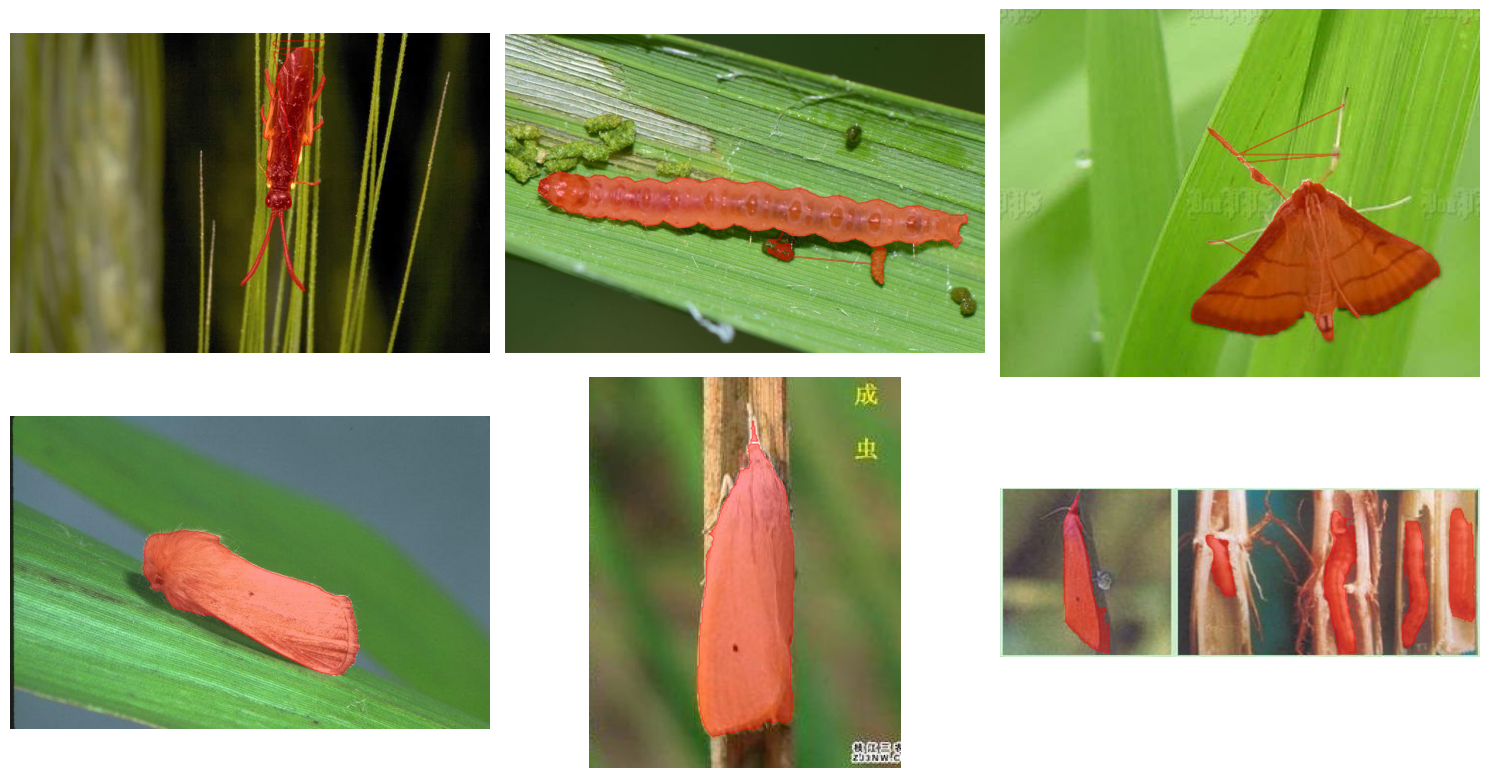

In [ ]:
files = random.sample(sorted((DS_DIR / "images" / "train").glob("*.*")), 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), files):
    img = Image.open(f).convert("RGB"); W, H = img.size
    ax.imshow(img)
    for line in (DS_DIR / "labels" / "train" / f"{f.stem}.txt").read_text().splitlines():
        pts = np.array(line.split()[1:], float).reshape(-1, 2) * [W, H]
        ax.add_patch(plt.Polygon(pts, closed=True, color="red", alpha=0.4))
    ax.axis("off")
plt.tight_layout(); plt.show()

## Step 7. Train the model
**YOLOv8s-seg** starts from a model that already knows general objects, so a small dataset is enough. It trains for up to 50 rounds (epochs) and stops early if the validation score stops improving. Flips, colour changes and the other common augmentations are applied automatically.

In [ ]:
model = YOLO("yolov8s-seg.pt")
model.train(data=str(DS_DIR / "data.yaml"), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=10,
            project=RUNS, name="pest", exist_ok=True, seed=SEED, workers=2)
best_path = Path(model.trainer.best)
print("Best weights:", best_path)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pest_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pest, nbs=64, nms=None, opset=None, optimize=False, optimi

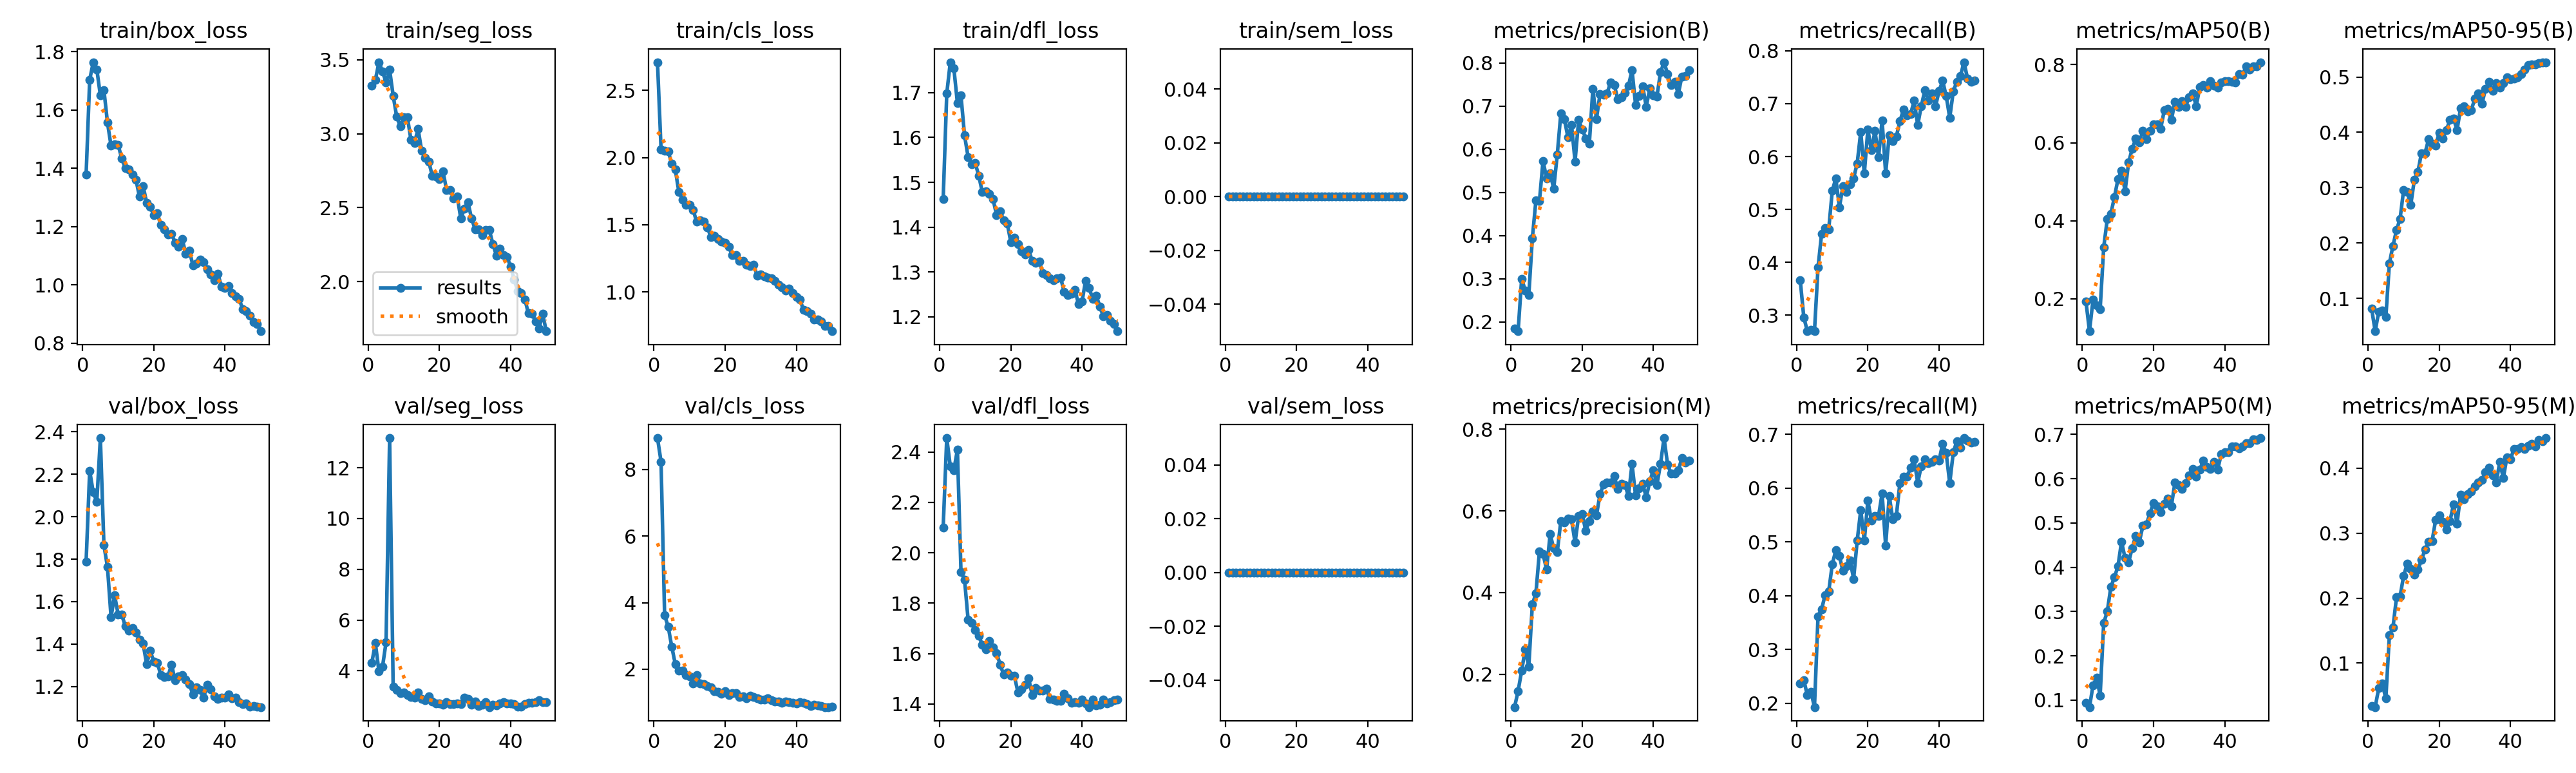

In [ ]:
from IPython.display import Image as IPImage, display
display(IPImage(str(best_path.parent.parent / "results.png")))

**How to read the training curves:** the loss lines should go down and flatten, and the mAP lines should go up and flatten. If the validation line gets worse while the training line keeps improving, the model is memorising the training photos (overfitting).

## Step 8. Grade the model on the test photos
**Terms in plain words**
- **IoU** (overlap): how much a predicted pest overlaps the labelled one. 0 means none, 1 means identical. A pest counts as found when the overlap is at least 0.5.
- **Recall:** of all real pests, the share the model finds.
- **Precision:** of all pests the model reports, the share that are real.
- **mAP@0.5:** one overall quality score from 0 to 1 that combines recall, precision and overlap. Higher is better.

Precision and recall below are taken at the confidence level that balances them best. Because the test photos are used to find that level, they can be slightly optimistic; mAP does not depend on it.

The **count accuracy** table is the most practical result: does the model report the right number of pests in a photo?

In [ ]:
model = YOLO(str(best_path))
m = model.val(data=str(DS_DIR / "data.yaml"), split="test", imgsz=IMGSZ, batch=4, plots=False, verbose=False)

print(f"Test photos: {len(test_df)} | real pests: {test_df['n_pests'].sum()}\n")
print(pd.DataFrame({"precision": [m.box.mp, m.seg.mp], "recall": [m.box.mr, m.seg.mr],
                    "mAP@0.5": [m.box.map50, m.seg.map50], "mAP@0.5-0.95": [m.box.map, m.seg.map]},
                   index=["boxes", "outlines (masks)"]).round(3))

# pest count per photo: real vs predicted
rows = []
for r in test_df.itertuples():
    f = DS_DIR / "images" / "test" / Path(r.path).name
    res = model.predict(str(f), imgsz=IMGSZ, conf=CONF, verbose=False)[0]
    rows.append({"file": Path(r.path).name, "true": len(r.boxes), "pred": len(res.boxes)})
cnt = pd.DataFrame(rows)
cnt["error"] = (cnt["pred"] - cnt["true"]).abs()

print(f"\nCount accuracy at confidence {CONF}:")
print(f"  Count exactly right:                {(cnt['error'] == 0).mean():.1%}")
print(f"  Count off by at most 1:             {(cnt['error'] <= 1).mean():.1%}")
print(f"  Photos where at least 1 pest found: {(cnt['pred'] > 0).mean():.1%}")
print(f"  Average count error:                {cnt['error'].mean():.2f} pests per photo")
print(f"  Total predicted vs real pests:      {cnt['pred'].sum()} vs {cnt['true'].sum()}")

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-seg summary (fused): 85 layers, 11,779,987 parameters, 0 gradients, 39.9 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 8.1±4.2 MB/s, size: 17.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/pest_yolo/labels/test... 290 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 290/290 542.5it/s 0.5s
val: /content/pest_yolo/images/test/01276.jpg: 1 duplicate labels removed
val: New cache created: /content/pest_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 15.6it/s 4.7s
                   all        290        469      0.818      0.736      0.807      0.544       0.75      0.677      0.703      0.458
Speed: 0.9ms preprocess, 9.

## Step 9. Look at the predictions
Random test photos with the pests the model found (outline, box and confidence score).

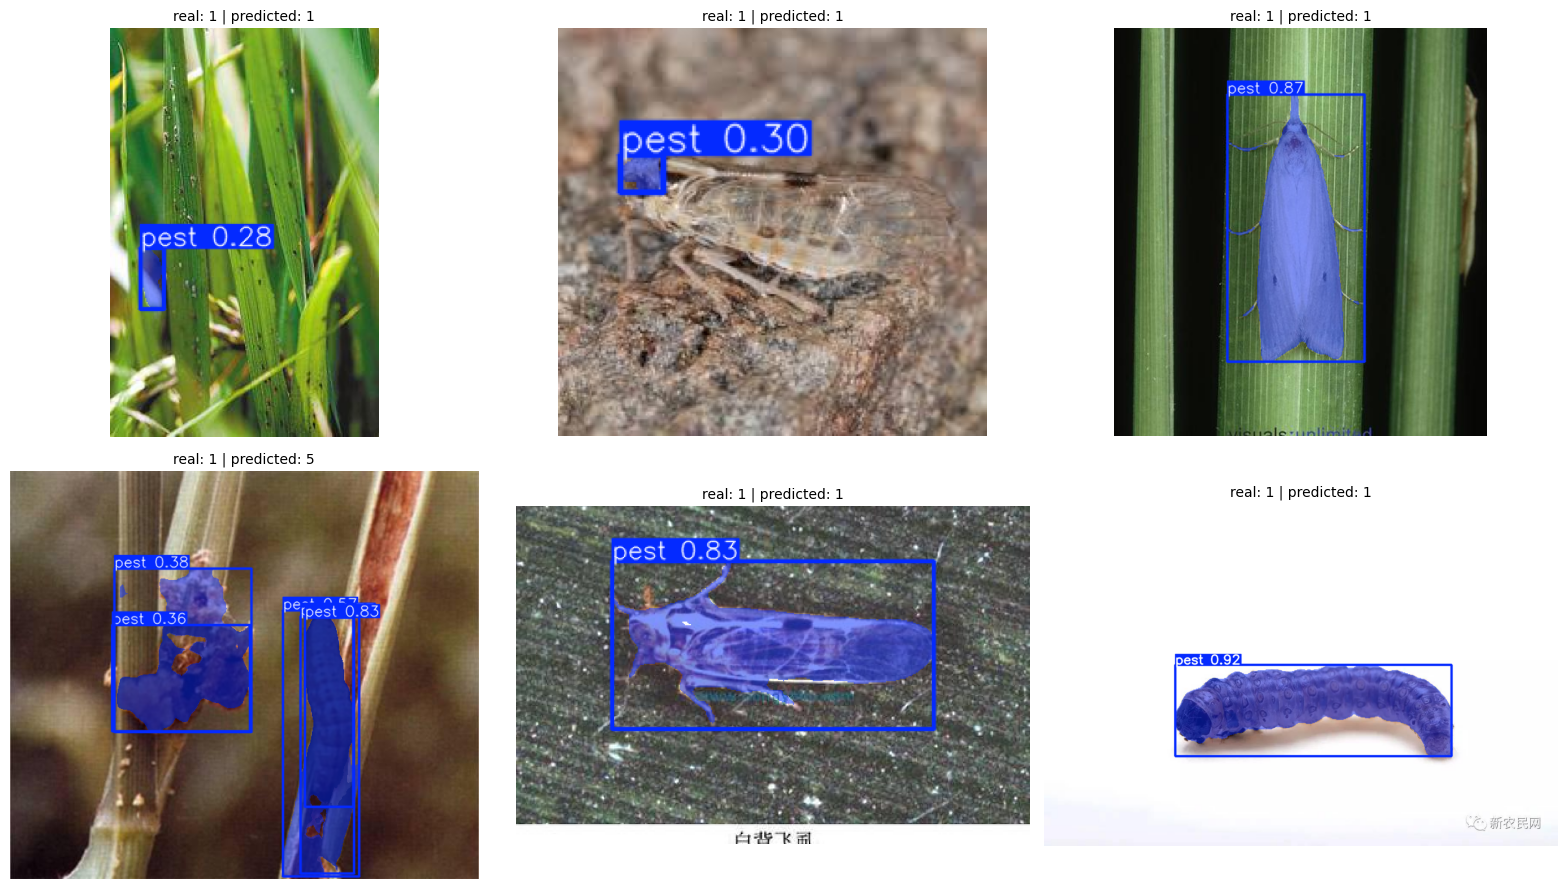

Photos with the biggest count error:
      file  true  pred  error
05564.jpg    34    45     11
03482.jpg     1     8      7
05411.jpg     8     2      6
25487.jpg     1     6      5
05417.jpg    10     5      5


In [ ]:
sample = cnt.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    res = model.predict(str(DS_DIR / "images" / "test" / row["file"]), imgsz=IMGSZ, conf=CONF, verbose=False)[0]
    ax.imshow(res.plot()[:, :, ::-1])                          # BGR -> RGB
    ax.set_title(f"real: {row['true']} | predicted: {row['pred']}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

worst = cnt.sort_values("error", ascending=False).head(5)
print("Photos with the biggest count error:\n", worst.to_string(index=False))

## Step 10. Detect pests on any photo and save the model
Change the path to any crop photo (for example, upload your own to Colab).

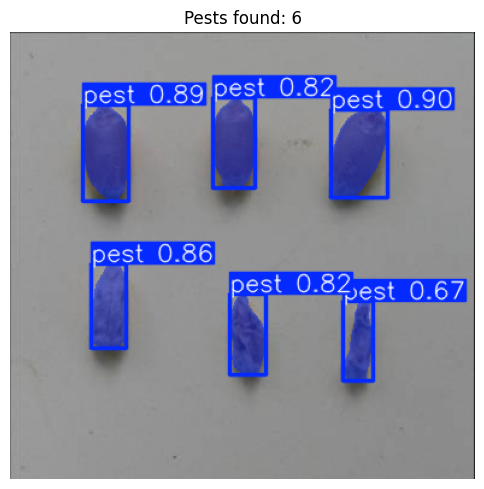

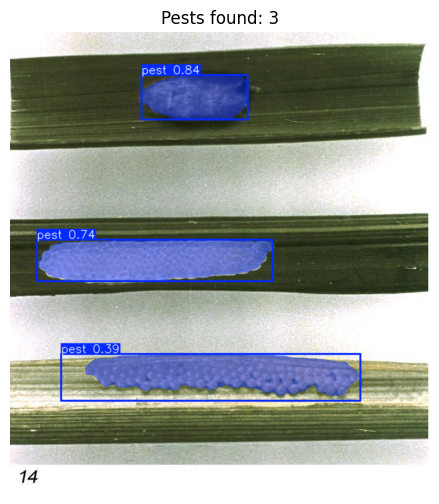

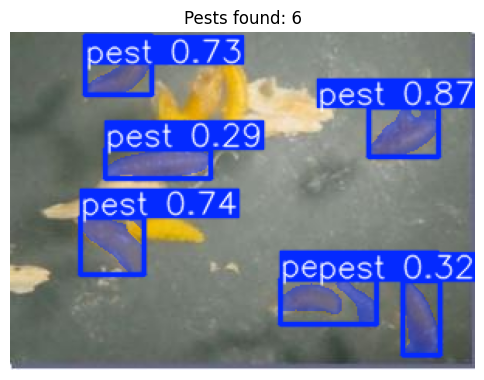

Saved: pest_model.pt


In [ ]:
def detect_pests(img_path, conf=CONF):
    res = model.predict(img_path, imgsz=IMGSZ, conf=conf, verbose=False)[0]
    plt.figure(figsize=(6, 6)); plt.imshow(res.plot()[:, :, ::-1]); plt.axis("off")
    plt.title(f"Pests found: {len(res.boxes)}"); plt.show()
    return len(res.boxes)

for p in test_df["path"].head(3):
    detect_pests(p)

shutil.copy(best_path, "pest_model.pt")      # the trained model; download it from the Colab file panel
print("Saved: pest_model.pt")

## Step 11. Project summary and conclusion

### Approach
1. Downloaded the photos and XML annotations (boxes in 11 pest folders) and cleaned them: merged several XML files per photo, removed the empty file and broken boxes. Because the `<name>` field was unreliable, all pests are one class, "pest".
2. Split the photos 70/15/15 by photo, stratified by pest type. The test set was used only once.
3. Used **SAM** to draw an outline inside every box, keeping it only when its size was sensible and otherwise using the box.
4. Trained **YOLOv8s-seg** (pretrained, up to 50 epochs with early stopping) to find, outline and score each pest separately.
5. Evaluated on unseen test photos with precision, recall, mAP@0.5 and the accuracy of the pest count.

### Model used
**YOLOv8s-seg (instance segmentation, Ultralytics)**: it returns, for every pest, an outline, a box and a confidence score, so pests can be counted. It is pretrained on general images and fine-tuned on this dataset. Masks for training come from SAM.

### Results
Evaluated on 290 test photos (470 real pests) that the model never saw during training.

| Test metric | Boxes | Outlines (masks) |
|---|---|---|
| Precision | 0.818 | 0.750 |
| Recall | 0.736 | 0.677 |
| mAP@0.5 | 0.807 | 0.703 |
| mAP@0.5-0.95 | 0.544 | 0.458 |

- Pest count exactly right: **67.2%** of photos; off by at most 1: **89.0%**; average count error 0.57 pests per photo.
- Photos where at least one pest was found: **93.8%**.
- Total pests predicted vs real: 534 vs 470 (the model tends to add a few extra detections).
- The validation mask mAP@0.5 (0.692) is close to the test value (0.703), so the test result is not inflated by memorising.

### Conclusion
The YOLOv8s-seg model finds and outlines individual pests with a mask mAP@0.5 of 0.70 (box mAP@0.5 0.81). With boxes it finds about 74% of the real pests (recall 0.74, precision 0.82). It reports the pest count correctly in 67% of test photos and within one pest in 89%, and finds at least one pest in 94% of photos, so it can be used to estimate how many pests are present. In the example predictions it works best on large, clearly visible pests (confidence 0.8 to 0.9) and is weakest on tiny pests and cluttered or crowded photos, where it adds extra detections (534 pests predicted against 470 real).

